# Analiza danych przestrzennych - ćwiczenia laboratoryjne 2025/2026

Ten notatnik zalicza się do grupy zestawów zadań, na podstawie których odbywa się zaliczenie ćwiczeń i podlega zwrotowi do oceny w ustalonym na zajęciach terminie.

Uwagi i wytyczne ogólne dotyczące uzupełniania i oceny notatnika:
- Podczas wykonywania zadań należy korzystać wyłącznie z pakietów zaimportowanych na początku notatnika oraz z pakietów wchodzących w skład standardowej biblioteki Pythona, które można zaimportować samodzielnie we wskazanej komórce notatnika.
- Swoje rozwiązania należy wprowadzać wyłącznie w miejce następujących fragmentów kodu:<br/> `# YOUR CODE HERE`<br/> `raise NotImplementedError()`<br/> 
a odpowiedzi tekstowe w komórkach oznaczonych hasłem:<br/> 
`YOUR ANSWER HERE`<br/> 
Nie należy w żaden sposób modyfikować pozostałych fragmentów kodu oraz innych elementów notatnika, w szczególności dodawać lub usuwać komórek oraz zmieniać nazwy pliku.
- Jeżeli zestaw zadań wymaga skorzystania z fragmentów kodu opracowanego w ramach wcześniejszych zestawów zadań należy je umieścić we wskazanej komórce notatnika.
- Otrzymywane wyniki i odpowiedzi mają być rezultatem wykonania napisanego kodu, odpowiedzi uzupełniane manualnie nie podlegają ocenie.
- Zawarte w notatniku automatyczne testy mają charakter poglądowy. Dotyczą one wybranych aspektów zadań i mają na celu wyłapać podstawowe błędy. Przejście przez kod wszystkich testów nie oznacza, że zadanie jest wykonane w całości poprawnie i zostanie ocenione na maksymalną liczbę punktów.
- Zadania należy wykonać w taki sposób, aby podczas wykonywania kodu nie zostały wyświetlone żadne ostrzeżenia.
- Zadania, które powodują wyświetlenie komunikatu o błędzie przerywającym wykonywanie kodu nie podlegają ocenie.
- W treści niektórych zadań mogą znaleźć się przykładowe schematy ich rozwiązania lub przykładowe schematy istotnych części rozwiązania. Nie zawsze są to rozwiązania optymalne pod kątem długości kodu lub prostoty rozwiązania.  Ich celem jest klarowne rozbicie pracy na kroki i ułatwienie samodzielnej weryfikacji wyników na każdym etapie. Należy je traktować wyłącznie poglądowo, a nie jako jedyne dopuszczalne rozwiązania. Ocenie podlega poprawność merytoryczna rozwiązania, jego kompletność oraz zgodność z wymaganiami, a nie konkretna forma zapisu.
- Dla zachowania przejrzystości i łatwego odnajdywania informacji w treści zadań podawane są pełne nazwy funkcji i klas wraz z nazwami pakietów (np. `pandas.read_csv()`, `geopandas.GeoDataFrame.to_crs`). W notatniku te same obiekty są dostępne przez skrótowe aliasy (np. `pd.read_csv()`, `gpd.GeoDataFrame.to_crs`).

Uwagi i wytyczne ogólne dotyczące wizualizacji wyników:
- Wszystkie wykresy powinny być wykonane w jednolitym, przejrzystym i czytelnym stylu, posiadać odpowiednio dobrane proporcje i zakresy wartości osi.
- Figury powinny mieć ustawione białe tło, tak, aby niezależnie od ustawień notatnika wszystkie elementy wykresów były dobrze widoczne (domyślnie tło jest przeźroczyste co może powodować problemy w notatnikach z ustawionym ciemnym tłem). Rozmiar poziomy figur nie powinien przekraczać 20 cali.
- Wykresy oraz ich osie powinny mieć nadane tytuły. Jeżeli w obrębie figury znajduje się więcej niż jeden wykres to figura również powinna mieć nadany tytuł.

Przed odesłaniem zestawu zadań do oceny proszę uzupełnić komórkę z danymi autorów rozwiązania (nazwa zespołu oraz imiona, nazwiska i numery indeksów członków zespołu) oraz upewnić się, że notatnik działa zgodnie z oczekiwaniami. W tym celu należy skorzystać z opcji **Restart Kernel and Run All Cells...** dostępnej na górnej belce notatnika pod symbolem $\blacktriangleright\blacktriangleright$.

Nazwa zespołu: GIN12  
Członkowie:  
Michał Kuśnierz 426683,  
Tymoteusz Chrzan 426173,  
Tymoteusz Hajduk 428250

---

## Zestaw zadań 7: Badanie intensywności procesów punktowych oraz relacji między punktami (część 1)

In [1]:
import numpy as np
import pandas as pd
import scipy as sp
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
import KDEpy as kde
import shapely

In [2]:
# Miejsce do importu pakietów wchodzących w skład standardowej biblioteki Pythona oraz ustawienie opcji wykorzystywanych pakietów

### Wczytanie danych
Poniższy kod wczytuje do zmiennych `poland`, `points_1`, `points_2`, `points_3` oraz `test_points` dane z pliku data.gpkg.

In [3]:
poland = gpd.read_file("data.gpkg", layer='poland')
poland

,Nazwa,geometry
0,Polska,"POLYGON ((495817.822 183473.276, 495778.757 18..."


In [4]:
points_1 = gpd.read_file("data.gpkg", layer='points_R')
points_1.head()

,geometry
0,POINT (746726.814 164535.535)
1,POINT (561669.012 179254.158)
2,POINT (575522.076 176268.791)
3,POINT (727348.477 178177.739)
4,POINT (749495.901 176165.143)


In [5]:
points_2 = gpd.read_file("data.gpkg", layer='points_P')
points_2.head()

,geometry
0,POINT (458336.668 682611.54)
1,POINT (264451.331 421768.917)
2,POINT (716458.063 211411.884)
3,POINT (333437.357 309193.537)
4,POINT (438396.636 631242.241)


In [6]:
points_3 = gpd.read_file("data.gpkg", layer='points_T')
points_3.head()

,geometry
0,POINT (638062.941 689433.083)
1,POINT (625542.51 692000.369)
2,POINT (638701.807 697065.653)
3,POINT (649499.586 696696.79)
4,POINT (650911.338 705624.982)


In [7]:
test_points = gpd.read_file("data.gpkg", layer='test_points')
test_points.head()

,geometry
0,POINT (364732.092 723385.55)
1,POINT (309246.986 665351.724)
2,POINT (352441.728 328023.909)
3,POINT (330186.768 278858.464)
4,POINT (338057.193 310040.858)


### Uwagi do wykonania zadań
We wszystkich zadaniach należy przyjąć, że pracujemy w płaskim układzie współrzędnych (układzie odniesienia opartym na odwzorowaniu kartograficznym na płaszczyznę). Dołączona do zestawu zadań tablice z rozkładami punktów oraz z granicami Polski zapisane są w układzie EPSG:2180.

### Zadanie 1: Generowanie siatki prostokątów i jej przycinanie do obszaru poligonu [8 pkt]

#### a) Przygotowanie funkcji

Przygotuj funkcję `rectangular_grid_over_polygon()`, która będzie generować siatkę prostokątnych komórek na obszarze ograniczonym danym poligonem oraz przycinać skrajne komórki do jego kształtu.

Algorytm postępowania:

1. Za pomocą własności `shapely.geometry.polygon.Polygon.bounds` odczytaj zakres współrzędnych poligonu, w obrębie którego ma być wygenerowana siatka prostokątów.

2. Wygeneruj równomierne współrzędne granic komórek na osi X i Y przy użyciu funkcji `numpy.linspace()` lub `numpy.arange()`.

3. Korzystając z funkcji `numpy.meshgrid()` utwórz 4 macierze określające współrzędne dolnych (`x0`, `y0`) i górnych (`x1`, `y1`) narożników prostokątów. Operacja ta wymaga dwukrotnego wywołania funkcji `numpy.meshgrid()` - osobno dla dolnych i górnych narożników prostokątów.

4. Wygeneruj prostokątne geometrie komórek siatki w sposób zwektoryzowany (wszystkie na raz), korzystając z funkcji `shapely.box()`, co pozwoli stworzyć całą siatkę bez użycia pętli.

5. Wykorzystując funkcję `shapely.intersection()` wykonaj operację przycięcia komórek siatki przez poligon.

6. Korzystając z funkcji `shapely.is_empty()` odfiltruj komórki, które po operacji przycianania mają puste geometre (leżą w całości poza poligonem). Przydatny może się tutaj okazać operator `~` (jeżeli `mask = numpy.array([True, False, True])` to `~mask` daje: `numpy.array([False, True, False]`)

7. Utwórz obiekt `geopandas.GeoDataFrame` ustawiając kolumnę geometrii oraz przypisując właściwy układ odniesienia.

8. Zwróć tablicę zawierającą komórki siatki ograniczone do obszaru poligonu.

In [8]:
"""
    Parameters
    -------
    polygon: shapely.geometry.polygon.Polygon
        Geometria poligonu, w obrębie którego mają zostać wygenerowane punkty.
    crs: str, int, pyproj.crs.crs.CRS
        Układ odniesienia przypisany do wynikowego GeoDataFrame.
        Powinien odpowiadać układowi współrzędnych wejściowego poligonu.
    bins: list
        Lista określająca liczbę punktów w siatce w poziomie i w pionie.
        Przykład: [20, 10]

    Returns
    -------
    grid : geopandas.GeoDataFrame
        Tablica zawierająca prostokątne komórki siatki, przycięte do obszaru 
        wejściowego poligonu i zapisane w układzie odniesienia `crs`.
    """
def rectangular_grid_over_polygon(polygon, crs, bins):
    minx, miny, maxx, maxy = polygon.bounds
    nx, ny = bins

    x_edges = np.linspace(minx, maxx, nx + 1)
    y_edges = np.linspace(miny, maxy, ny + 1)

    x0, y0 = np.meshgrid(x_edges[:-1], y_edges[:-1])
    x1, y1 = np.meshgrid(x_edges[1:],  y_edges[1:])

    cells = shapely.box(x0, y0, x1, y1).ravel()

    clipped = shapely.intersection(cells, polygon)

    mask = ~shapely.is_empty(clipped)
    clipped = clipped[mask]

    grid = gpd.GeoDataFrame(geometry=gpd.GeoSeries(clipped), crs=crs)
    grid = grid.reset_index(drop=True)

    return grid

In [9]:
# Komórka testowa
test_grid = rectangular_grid_over_polygon(poland.geometry[0], crs="2180", bins=[15,15])

assert type(test_grid) == gpd.geodataframe.GeoDataFrame
assert test_grid.shape == (193, 1)
assert list(test_grid.columns) == ['geometry']
assert test_grid.crs == "epsg:2180"
assert np.isclose(test_grid.area.mean(), 1619205412.320454)

#### b) Zastosowanie funkcji i wizualizacja wyniku

Wykorzystaj funkcję `rectangular_grid_over_polygon()` przygotowaną w poprzednim podpunkcie do wygenerowania siatki 30x30 prostokątnych komórek dopasowanych do granic wczytanego do notatnika poligonu (`poland`). Wynik zapisz do zmiennej `grid`.

Następnie, korzystając z funkcji pakietu matplotlib oraz funkcji `geopandas.GeoDataFrame.plot()` zwizualizuj wynik. Wizualizacja powinna zawierać:
- granice poligonu, w obrębie którego generowana jest siatka,
- granice przygotowanej siatki podobszarów,
- wybrany przez siebie rozkład punktów (`points_1`, `points_2` lub `points_3`).

Przygotuj figurę zgodnie z wytycznymi z nagłówka notatnika. Ustaw inne od domyślnych parametry wykresu oraz wizualizowanych obiektów (wielkość figury, kolory, grubość linii, wielkość punktów itp.) tak aby wygenerowana mapa była przejrzysta i czytelna.

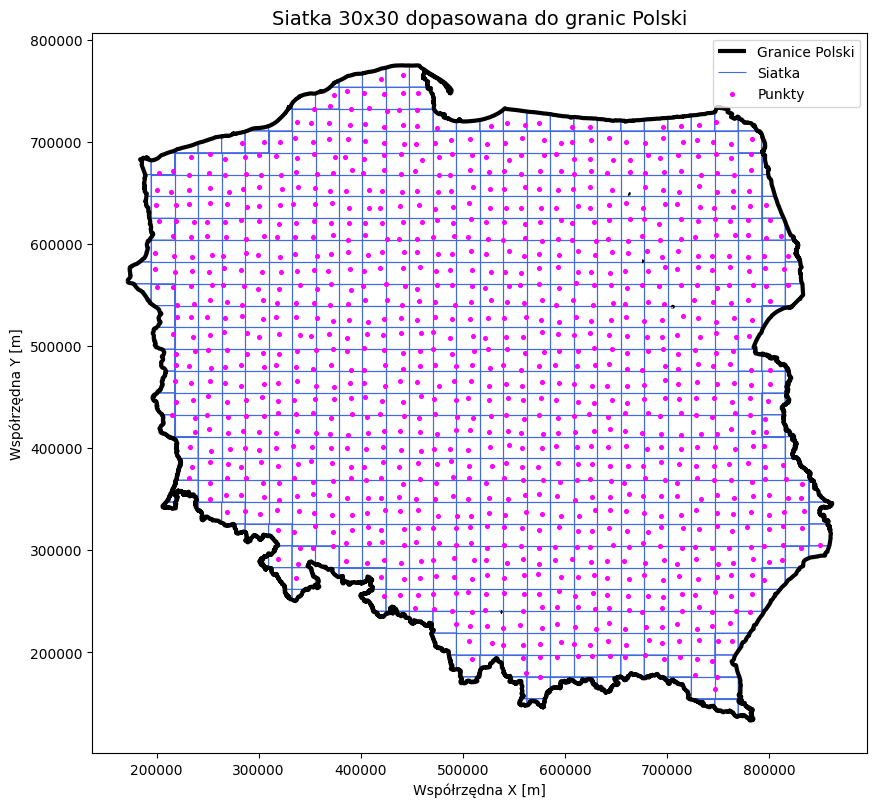

In [10]:
grid = rectangular_grid_over_polygon(poland.geometry.iloc[0], poland.crs, bins=[30, 30])

fig, ax = plt.subplots(figsize=(10, 10))

poland.boundary.plot(ax=ax, color="black", linewidth=3, label="Granice Polski", zorder=2)

grid.boundary.plot(ax=ax, color="royalblue", linewidth=0.8, label="Siatka", zorder=1)

points_1.plot(ax=ax, color="magenta", markersize=7, label="Punkty", zorder=3)

ax.set_title("Siatka 30x30 dopasowana do granic Polski", fontsize=14)
ax.set_xlabel("Współrzędna X [m]")
ax.set_ylabel("Współrzędna Y [m]")
ax.legend()

plt.show()

### Zadanie 2: Obliczanie statystyk rozkładu metodą szacowania lokalnego [12 pkt]

#### a) Przygotowanie funkcji
 
Przygotuj funkcję `point_statistic_on_subregions()`, która dla zadanego rozkładu punków oraz siatki podobszarów obliczy statystykę punktową na każdej jednostce podziału. Funkcja powinna umożliwiać wyliczenie liczby punktów (`counts`) lub intensywności procesu (`intensity`) w obrębie poszczególnych podobszarów.

Algorytm postępowania:

1. Korzystając z `geopandas.sjoin()` wykonaj przestrzenne połączenie pomiędzy punktami a podobszarami. W tym celu odpowiednio zdefiniuj wartości parametrów `how` i `predicate` tak, aby otrzymać tablicę, w której do każdego z punktów jest przyporządkowany indeks podobszaru, w którym się znajduje.

2. Wykorzystaj funkcje `pandas.DataFrame.groupby()` do pogrupowania punktów znajdujących się w poszczególnych obszarach, korzystając z grupowania po indeksie podobszaru nadanym podczas poprzedniej operacji. Nastepnie korzystając z funkcji `pandas.DataFrame.size()` określ wielkość każdej z grup (liczba punktów przypadających na obszar.

3. Utwórz nowy obiekt `geopandas.GeoDataFrame`, zawierający wyłącznie geometrię podobszarów oraz ustawiony odpowiedni układ odniesienia (`crs`).  
   Ten obiekt będzie służył jako struktura wynikowa niezależna od wejściowego `subregions` co zapobiegnie nadpisywaniu zmiennej wejściowej podczas kolejnych wykonań funkcji.

4. W zależności od wybranej statystyki dodaj do utworzonej tablicy z geometriami podobszarów jedną z następujących kolumn:
   - `counts`: przypisz liczbę punktów do kolumny "counts", uzupełniając brakujące wartości zerami za pomocą funkcji `pandas.DataFrame.fillna()`.
   - `intensity`:  
     - wylicz pola powierzchni wszystkich podobszarów,  
     - oblicz intensywność jako iloraz liczby punktów i pola powierzchni podobszaru,
     - przypisz intensywność do kolumny "intensity", uzupełniając brakujące wartości zerami za pomocą funkcji `pandas.DataFrame.fillna()`.
5. Zwróć obiekt `geopandas.GeoDataFrame` zawierający geometrię oraz wybraną statystykę punktową.

In [11]:
"""
    Parameters
    -------
    points : geopandas.GeoDataFrame
        Zbiór punktów wejściowych, na podstawie których estymowana jest intensywność.
    subregions : geopandas.GeoDataFrame
        Zbiór podobszarów poligonalnych, do których przypisywane są punkty.
    statistic : str
        Rodzaj statystyki obliczanej dla podobszarów:
        - "counts": liczba punktów przypadających na każdy podobszar,
        - "intensity": intensywność procesu (liczba punktów na jednostkę powierzchni podobszaru).

    Returns
    -------
    statistic_on_subregions : geopandas.GeoDataFrame
        Tablica zawierająca:
        - kolumnę "counts" lub "intensity" z wartościami oszacowanej statystyki,
        - geometrię  reprezentującą siatkę podobszarów.
    """

def point_statistic_on_subregions(points, subregions, statistic="counts"):
    joined = gpd.sjoin(points, subregions, how="left", predicate="within")

    counts = joined.groupby("index_right").size()

    result = gpd.GeoDataFrame(geometry=subregions.geometry.copy(), crs=subregions.crs)

    if statistic == "counts":
        result["counts"] = counts.reindex(result.index).fillna(0).astype(int)
        return result

    elif statistic == "intensity":
        areas = subregions.area
        intensity = counts / areas
        result["intensity"] = intensity.reindex(result.index).fillna(0)
        return result

    return counts, intensity

In [12]:
# Komórka testowa
test_statistic_1 = point_statistic_on_subregions(test_points, test_grid, statistic="counts")
assert type(test_statistic_1) == gpd.geodataframe.GeoDataFrame
assert test_statistic_1.shape == (193, 2)
assert set(test_statistic_1.columns) == set(['geometry', "counts"])
assert test_statistic_1.crs == "epsg:2180"
assert np.isclose(test_statistic_1["counts"].min(), 0)
assert np.isclose(test_statistic_1["counts"].mean(), 3.0414507772020727)
assert np.isclose(test_statistic_1["counts"].max(), 24)

test_statistic_2 = point_statistic_on_subregions(test_points, test_grid, statistic="intensity")
assert type(test_statistic_2) == gpd.geodataframe.GeoDataFrame
assert test_statistic_2.shape == (193, 2)
assert set(test_statistic_2.columns) == set(['geometry', "intensity"])
assert test_statistic_2.crs == "epsg:2180"
assert np.isclose(test_statistic_2["intensity"].min(), 0)
assert np.isclose(test_statistic_2["intensity"].mean(), 1.6538563114997573e-09)
assert np.isclose(test_statistic_2["intensity"].max(), 1.219019704515764e-08)

#### b) Zastosowanie funkcji i wizualizacja wyniku

Wykorzystaj funkcję `point_statistic_on_subregions()` przygotowaną w poprzednim podpunkcie do zbadania intensywności procesów punktowych dla wszystkich wczytanych do notatnika rozkładów (`points_1`, `points_2`, `points_3`). Analizę przeprowadź dla całego obszaru wczytanego do notatnika poligonu (`poland`) podzielonego na przygotowaną w poprzednim zadaniu siatkę podobszarów `grid`.

Wyznacz globalne minimum i maksimum wartości intensywności spośród wszystkich trzech rozkładów. Te dwie wartości zostaną wykorzystane do ustalenia wspólnej skali kolorów, tak aby histogramy były porównywalne pomiędzy procesami.

Następnie, korzystając z funkcji pakietu matplotlib oraz funkcji `geopandas.GeoDataFrame.plot()` zwizualizuj wynik na pojedynczej figurze (siatka wykresów 1x3). Wizualizacja dla każdego rozkładu powinna zawierać:
- granice poligonu, w obrębie którego generowana jest siatka,
- wizualizacja intensywności na podobszarach,
- rozkład punktowy, który został poddany analizie.

Dla wszystkich wykresów zastosuj tę samą kolorystykę (`cmap`) oraz ten sam zakres wartości (`vmin`, `vmax`), ustalony na podstawie wyznaczonych wcześniej globalnych ekstremów intensywności.

Przygotuj figurę zgodnie z wytycznymi z nagłówka notatnika. Ustaw inne od domyślnych parametry wykresu oraz wizualizowanych obiektów (wielkość figury, kolory, grubość linii, wielkość punktów itp.) tak aby wygenerowana mapa była przejrzysta i czytelna.

Globalne minimum intensywności: 0.0
Globalne maksimum intensywności: 2.234869458278901e-08


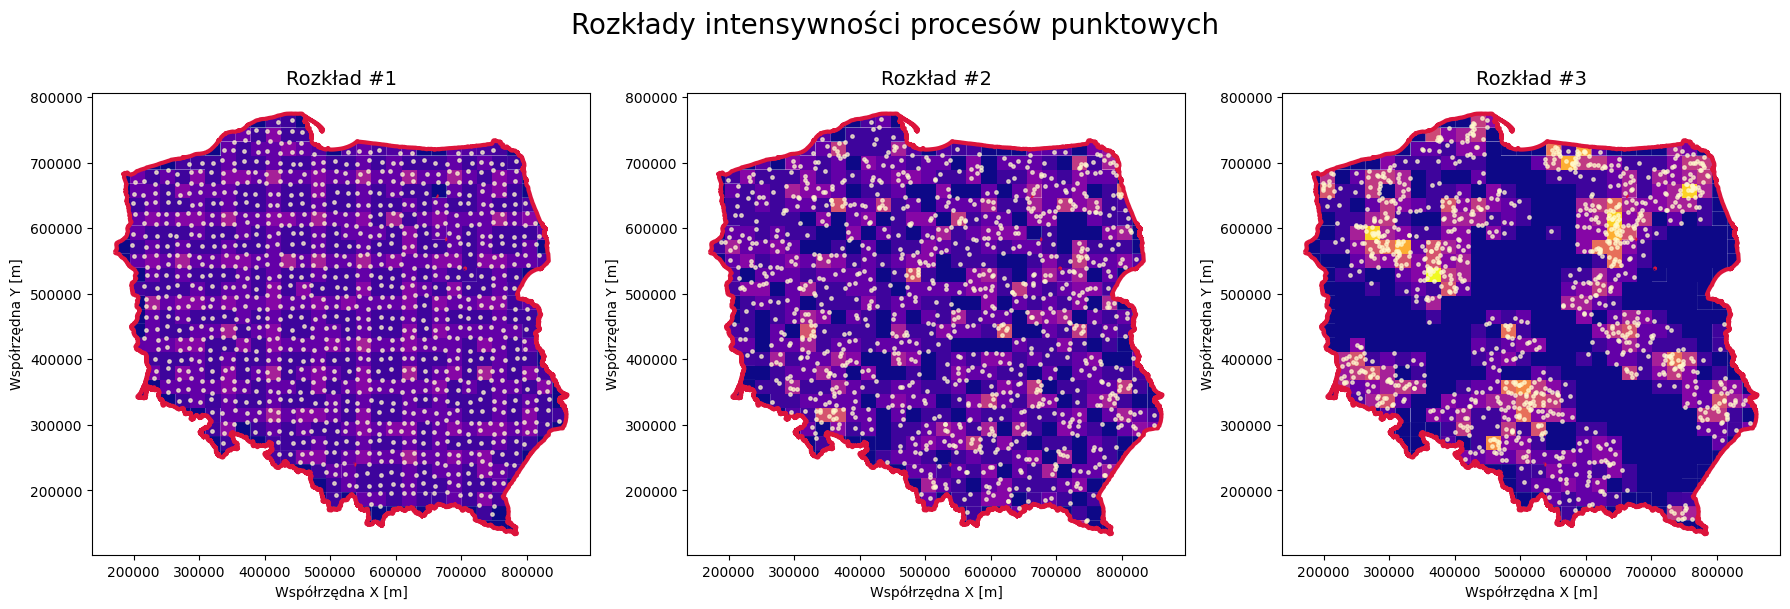

In [13]:
int_1 = point_statistic_on_subregions(points_1, grid, statistic="intensity")
int_2 = point_statistic_on_subregions(points_2, grid, statistic="intensity")
int_3 = point_statistic_on_subregions(points_3, grid, statistic="intensity")

global_min = min(int_1["intensity"].min(), int_2["intensity"].min(), int_3["intensity"].min())

global_max = max(int_1["intensity"].max(), int_2["intensity"].max(), int_3["intensity"].max())

print("Globalne minimum intensywności:", global_min)
print("Globalne maksimum intensywności:", global_max)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

ints = [int_1, int_2, int_3]
points = [points_1, points_2, points_3]
titles = ["Rozkład #1", "Rozkład #2", "Rozkład #3"]

for i in range(3):
    ax = axes[i]

    poland.boundary.plot(ax=ax, color="crimson", linewidth=3, zorder=3)
    ints[i].plot(ax=ax, column="intensity", cmap="plasma", vmin=global_min, vmax=global_max, linewidth=0.1, edgecolor="none", zorder=1)
    points[i].plot(ax=ax, color="lemonchiffon", markersize=6, alpha=0.7, zorder=4)

    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel("Współrzędna X [m]")
    ax.set_ylabel("Współrzędna Y [m]")

fig.suptitle("Rozkłady intensywności procesów punktowych", fontsize=20, y=0.99)
plt.tight_layout()

plt.show()

### Zadanie 2: Badanie intensywności procesu punktowego metodą funkcji jądrowej [12 pkt]

Przygotuj funkcję `kde_intensity_estimation()`, która dla zadanego zbioru punktów oszacuje intensywność przestrzenną metodą estymacji jądrowej (KDE). Funkcja powinna umożliwiać wybór jądra, szerokości pasma oraz siatki punktów testowych, dla których szacowana będzie intensywność procesu. Wynik powinien zostać ograniczony wyłącznie do obszaru wejściowego poligonu.

Algorytm postępowania:

1. Korzystając z własności `geopandas.GeoDataFrame.geometry.x` i `geopandas.GeoDataFrame.geometry.y` wyodrębnij z geometrii rozkładu współrzędne X i Y poszczególnych punktów. Następnie korzystajac z `numpy.vstack()` oraz transpozycji lub `numpy.concat()` skonstruuj macierz współrzędnych o wymiarach `(n, 2)`, gdzie n to liczba punktów rozkładu.

2. Skorzystaj z klasy `KDEpy.FFTKDE` do utworzenia modelu KDE określając wartości argumentów odpowiedzialnych za typ jądra oraz szerokość pasma. Następnie wywołaj kolejno na utworzonym obiekcie `KDEpy.FFTKDE.fit()` oraz `KDEpy.FFTKDE.evaluate()` z odpowiednio dobranymi argumentami, aby dopasować model do rozkładu punktów oraz dokonać ewaluacji modelu na siatce punktów pomiarowych. Operacja ta zwraca dwie macierze - pierwsza zawiera współrzędne punktów pomiarowych, a druga wyliczone dla nich wartości intensywności.

3. Zbuduj obiekt `geopandas.GeoDataFrame` zawierający kolumnę "intensity" z wyliczonymi wartościami intensywności oraz geometrię punktów pomiarowych zbudowaną na podstawie otrzymanej macierzy za pomocą funkcji `geopandas.points_from_xy()`.

4. Skorzystaj z funkcji `geopandas.GeoSeries.within()` w celu odfiltrowania punktów znajdujących się poza obszarem poligonu. Pamiętaj o zresetowaniu indeksów wynikowej tablicy.

5. Zwróć obiekt `geopandas.GeoDataFrame` zawierający geometrię oraz obliczoną statystkę.

In [14]:
"""
    Parameters
    -------
    points : geopandas.GeoDataFrame
        Zbiór punktów wejściowych, na podstawie których estymowana jest intensywność.
    polygon : shapely.geometry.polygon.Polygon
        Poligon definiujący obszar, do którego ograniczony zostanie wynik estymacji KDE.
    kernel : str
        Nazwa jądra używanego w estymacji, np. "gaussian", "epa", "triangular".
    bandwidth : float
        Szerokość pasma, określająca stopień wygładzenia estymacji.
    grid : int, tuple, numpy.ndarray
        Liczba punktów siatki w poziomie i w pionie (gdy podano liczbę lub tuple) lub macierz punktów testowych,
        na których oceniana będzie gęstość. W przypadku przekazania liczby lub tuple, FFTKDE automatycznie wygeneruje równomierną siatkę punktów pomiarowych.

    Returns
    -------
    kde_estimation : geopandas.GeoDataFrame
        Tablica zawierająca:
        - kolumnę "intensity" z wartościami oszacowanej gęstości,
        - geometrię  reprezentującą lokalizacje punktów siatki pomiarowej.
    """

def kde_intensity_estimation(points, polygon, kernel, bandwidth, grid):
    x = points.geometry.x.values
    y = points.geometry.y.values
    coords = np.vstack((x, y)).T

    kde_model = kde.FFTKDE(kernel=kernel, bw=bandwidth)
    kde_model = kde_model.fit(coords)

    if isinstance(grid, (int, tuple)):
        eval_points, intensity = kde_model.evaluate(grid)
    else:
        sample_points = np.asarray(grid)
        intensity = kde_model.evaluate(sample_points)
        eval_points = sample_points

    gdf = gpd.GeoDataFrame(
        {"intensity": intensity},
        geometry=gpd.points_from_xy(eval_points[:, 0], eval_points[:, 1]),
        crs=points.crs
    )

    mask = polygon.covers(gdf.geometry)
    gdf = gdf[mask].reset_index(drop=True)

    return gdf

In [15]:
# Komórka testowa
test_kde = kde_intensity_estimation(test_points, poland.geometry[0], kernel="gaussian", bandwidth=1000, grid=100)

assert type(test_kde) == gpd.geodataframe.GeoDataFrame
assert test_kde.shape == (6751 , 2)
assert set(test_kde.columns) == set(['geometry', "intensity"])
assert test_kde.crs == "epsg:2180"
assert np.isclose(test_kde["intensity"].min(), 2.220446049250313e-16)
assert np.isclose(test_kde["intensity"].mean(), 2.3570098940829026e-11)
assert np.isclose(test_kde["intensity"].max(), 6.780752026456683e-10)

#### b) Zastosowanie funkcji i wizualizacja wyniku 

Wykorzystaj funkcję `kde_intensity_estimation()` przygotowaną w poprzednim podpunkcie do oszacowania intensywności przestrzennej procesów punktowych dla wszystkich wczytanych do notatnika rozkładów (`points_1`, `points_2`, `points_3`). Analizę przeprowadź dla całego obszaru wczytanego do notatnika poligonu (`poland`).

Wyznacz globalne minimum i maksimum wartości intensywności spośród wszystkich trzech rozkładów. Te dwie wartości zostaną wykorzystane do ustalenia wspólnej skali kolorów, tak aby histogramy były porównywalne pomiędzy procesami.

Przygotuj maskę geometryczną reprezentującą obszary znajdujące się poza granicami Polski. W tym celu:  
   - korzystając z `shapely.geometry.polygon.Polygon.bounds` oraz `shapely.geometry.box()` zbuduj prostokąt obejmujący cały analizowany obszar,
   - korzystając z `shapely.geometry.polygon.Polygon.difference()` wytnij z prostokąta poligon reprezentujący obszar analizy,
   - zbuduj obiekt `geopandas.GeoDataFrame` zawierający w kolumnie 'geometry' geometrię przygotowanej maski, z `crs` ustawionym na identyczny jak poligonu i analizowanego rozkładu puntków.
   Maska ta zostanie wykorzystana podczas wizualizacji w celu usunięcia z map wartości intensywności spoza granic Polski.

Następnie, korzystając z funkcji pakietu matplotlib oraz funkcji `geopandas.GeoDataFrame.plot()` zwizualizuj wynik na pojedynczej figurze (siatka wykresów 1x3). Wizualizacja dla każdego rozkładu powinna zawierać:
- granice poligonu, w obrębie którego generowana jest siatka,
- wizualizacja intensywności na podobszarach zrealizowana metodą konturową za pomocą funkcji `matplotlib.pyplot.tricontourf()`,
- maska zakrywająca obszar poza granicami poligonu,
- rozkład punktowy, który został poddany analizie.

Dla wszystkich wykresów zastosuj tę samą kolorystykę (`cmap`) oraz ten sam zakres wartości (`vmin`, `vmax`), ustalony na podstawie wyznaczonych wcześniej globalnych ekstremów intensywności.

Przygotuj figurę zgodnie z wytycznymi z nagłówka notatnika. Ustaw inne od domyślnych parametry wykresu oraz wizualizowanych obiektów (wielkość figury, kolory, grubość linii, wielkość punktów itp.) tak aby wygenerowana mapa była przejrzysta i czytelna.

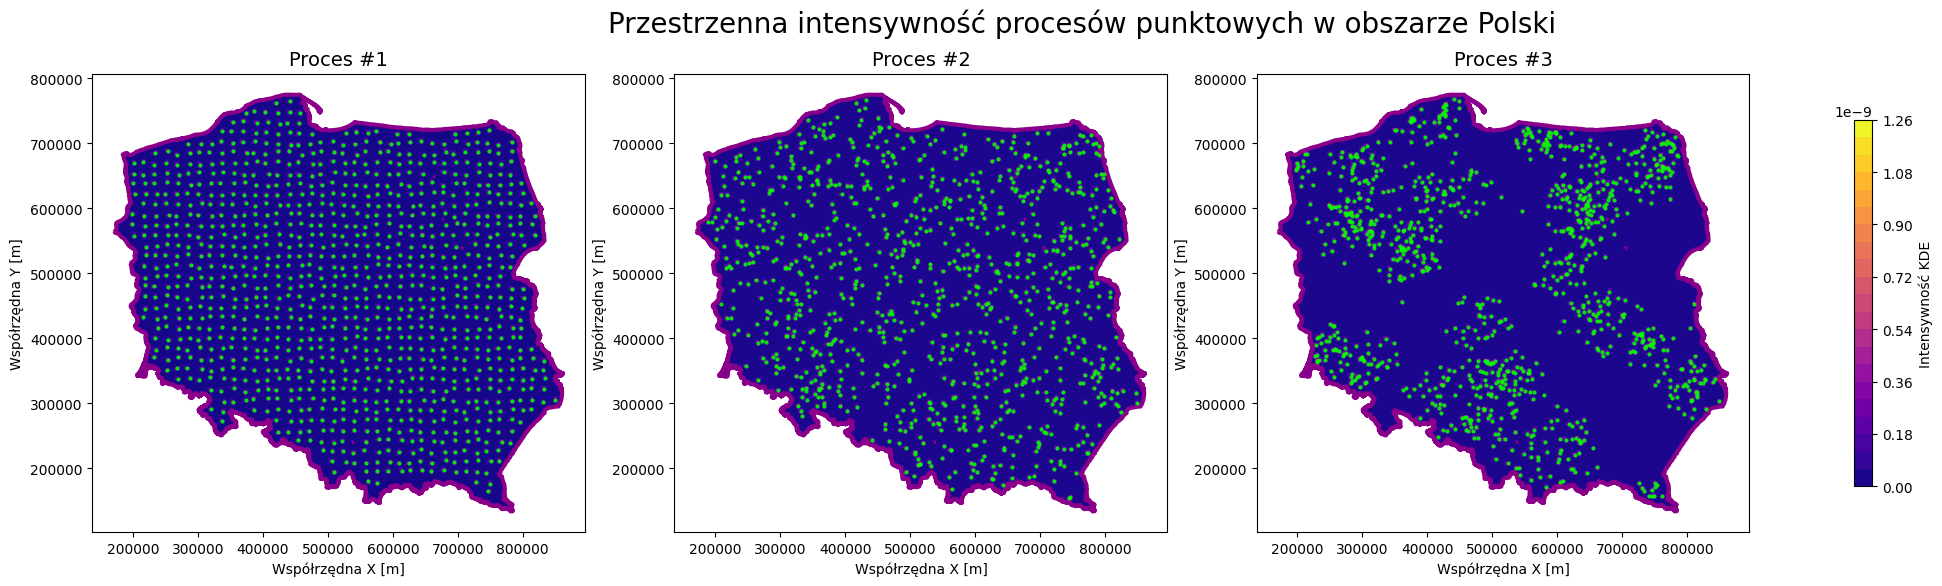

In [16]:
kde_1 = kde_intensity_estimation(points_1, poland.geometry.iloc[0], kernel="gaussian", bandwidth=500, grid=200)
kde_2 = kde_intensity_estimation(points_2, poland.geometry.iloc[0], kernel="gaussian", bandwidth=500, grid=200)
kde_3 = kde_intensity_estimation(points_3, poland.geometry.iloc[0], kernel="gaussian", bandwidth=500, grid=200)


global_min = min(kde_1["intensity"].min(), kde_2["intensity"].min(), kde_3["intensity"].min())
global_max = max(kde_1["intensity"].max(), kde_2["intensity"].max(), kde_3["intensity"].max())

poly = poland.geometry.iloc[0]
minx, miny, maxx, maxy = poly.bounds
rect = shapely.geometry.box(minx, miny, maxx, maxy)
mask_geom = rect.difference(poly)
mask_gdf = gpd.GeoDataFrame(geometry=[mask_geom], crs=poland.crs)

fig, axes = plt.subplots(1, 3, figsize=(22, 6))

kdes = [kde_1, kde_2, kde_3]
pts = [points_1, points_2, points_3]
titles = ["Proces #1", "Proces #2", "Proces #3"]

for ax, kde_gdf, pts_gdf, title in zip(axes, kdes, pts, titles):
    x = kde_gdf.geometry.x.values
    y = kde_gdf.geometry.y.values
    z = kde_gdf["intensity"].values

    cf = ax.tricontourf(x, y, z, levels=20, cmap="plasma", vmin=global_min, vmax=global_max)

    mask_gdf.plot(ax=ax, color="white", edgecolor="none", zorder=3)
    poland.boundary.plot(ax=ax, color="darkmagenta", linewidth=3, zorder=4)
    pts_gdf.plot(ax=ax, color="lime", markersize=4, alpha=0.8, zorder=5)

    ax.set_title(title, fontsize=14)
    ax.set_xlabel("Współrzędna X [m]")
    ax.set_ylabel("Współrzędna Y [m]")
    ax.set_aspect("equal")

fig.suptitle("Przestrzenna intensywność procesów punktowych w obszarze Polski", fontsize=20, y=0.97)
plt.tight_layout()
cbar = fig.colorbar(cf, ax=axes.ravel().tolist(), shrink=0.8)
cbar.set_label("Intensywność KDE")

plt.show()